
# MovieLens – Content-Based Filtering

## Obiettivo

In questo notebook costruiamo la **seconda componente del sistema di raccomandazione ibrido**: il **Content-Based Filtering**.

A differenza dell'Item-Based Collaborative Filtering, qui non usiamo la similarità tra i comportamenti degli utenti. La raccomandazione viene costruita a partire dalle **caratteristiche dei film** disponibili in MovieLens:

- `genres` da `movies.csv`;
- `tag` da `tags.csv`.

Il flusso sarà:

1. studio dei metadata disponibili;
2. analisi di generi e tag;
3. costruzione della rappresentazione testuale degli item;
4. vettorizzazione TF-IDF;
5. similarità Content-Based tra film;
6. costruzione del profilo contenutistico dell'utente;
7. raccomandazione Top-N;
8. valutazione offline con lo stesso protocollo usato per l'Item-Based;
9. confronto con una baseline di popolarità.

> Nota: MovieLens Latest Small non contiene trama, attori o descrizioni testuali dei film. Per questo il Content-Based viene costruito usando **generi e tag**.


## 1. Import delle librerie

In [1]:

from pathlib import Path
import urllib.request
import zipfile
import re

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.sparse import hstack, csr_matrix
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", lambda x: f"{x:.4f}")



## 2. Download e caricamento del dataset

Il notebook è autonomo: se `ml-latest-small` non è già presente nella cartella di lavoro, viene scaricato automaticamente dal sito ufficiale GroupLens.


In [2]:

DATA_DIR = Path("ml-latest-small")
ZIP_PATH = Path("ml-latest-small.zip")

if not DATA_DIR.exists():
    url = "https://files.grouplens.org/datasets/movielens/ml-latest-small.zip"

    print("Download del dataset...")
    urllib.request.urlretrieve(url, ZIP_PATH)

    print("Estrazione...")
    with zipfile.ZipFile(ZIP_PATH, "r") as z:
        z.extractall(".")

    print("Dataset pronto.")
else:
    print("Dataset già presente.")


Download del dataset...
Estrazione...
Dataset pronto.


In [3]:

ratings = pd.read_csv(DATA_DIR / "ratings.csv")
movies = pd.read_csv(DATA_DIR / "movies.csv")
tags = pd.read_csv(DATA_DIR / "tags.csv")

ratings["datetime"] = pd.to_datetime(ratings["timestamp"], unit="s")
tags["datetime"] = pd.to_datetime(tags["timestamp"], unit="s")

print("ratings:", ratings.shape)
print("movies :", movies.shape)
print("tags   :", tags.shape)


ratings: (100836, 5)
movies : (9742, 3)
tags   : (3683, 5)


In [4]:

display(movies.head())
display(tags.head())


,movieId,title,genres
0,1,Toy Story (1995),Adventure|Animation|Children|Comedy|Fantasy
1,2,Jumanji (1995),Adventure|Children|Fantasy
2,3,Grumpier Old Men (1995),Comedy|Romance
3,4,Waiting to Exhale (1995),Comedy|Drama|Romance
4,5,Father of the Bride Part II (1995),Comedy


,userId,movieId,tag,timestamp,datetime
0,2,60756,funny,1445714994,2015-10-24 19:29:54
1,2,60756,Highly quotable,1445714996,2015-10-24 19:29:56
2,2,60756,will ferrell,1445714992,2015-10-24 19:29:52
3,2,89774,Boxing story,1445715207,2015-10-24 19:33:27
4,2,89774,MMA,1445715200,2015-10-24 19:33:20



# 3. Studio dei contenuti disponibili

Per costruire un Content-Based dobbiamo prima capire **quali informazioni descrivono gli item**.

In MovieLens abbiamo:

- `title`: titolo del film;
- `genres`: uno o più generi separati da `|`;
- `tags`: parole o brevi espressioni assegnate dagli utenti ai film.

Il titolo verrà mantenuto per l'identificazione del film, mentre il modello userà principalmente **generi e tag**.


In [5]:

print("Numero di film:", movies["movieId"].nunique())
print("Numero di tag:", len(tags))
print("Film con almeno un tag:", tags["movieId"].nunique())
print("Utenti che hanno assegnato almeno un tag:", tags["userId"].nunique())

tag_coverage = tags["movieId"].nunique() / movies["movieId"].nunique()

print(f"Copertura dei tag sul catalogo: {tag_coverage:.2%}")


Numero di film: 9742
Numero di tag: 3683
Film con almeno un tag: 1572
Utenti che hanno assegnato almeno un tag: 58
Copertura dei tag sul catalogo: 16.14%


## 3.1 Valori mancanti e duplicati

In [6]:

print("Missing values - movies")
display(movies.isna().sum())

print("Missing values - tags")
display(tags.isna().sum())

print("MovieId duplicati in movies:", movies.duplicated("movieId").sum())


Missing values - movies


,0
movieId,0
title,0
genres,0


Missing values - tags


,0
userId,0
movieId,0
tag,0
timestamp,0
datetime,0


MovieId duplicati in movies: 0



# 4. Analisi dei generi


In [7]:

movies["genre_list"] = movies["genres"].str.split("|")

all_genres = (
    movies["genre_list"]
    .explode()
    .value_counts()
)

display(all_genres)


,count
genre_list,
Drama,4361
Comedy,3756
Thriller,1894
Action,1828
Romance,1596
Adventure,1263
Crime,1199
Sci-Fi,980
Horror,978


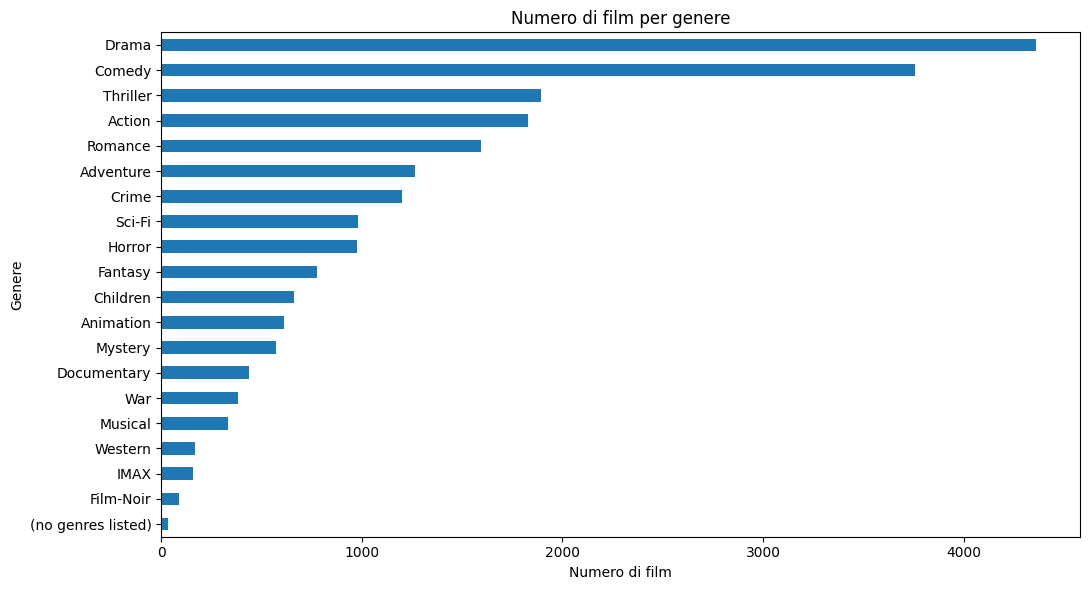

In [8]:

plt.figure(figsize=(11, 6))

all_genres.sort_values().plot(kind="barh")

plt.title("Numero di film per genere")
plt.xlabel("Numero di film")
plt.ylabel("Genere")

plt.tight_layout()
plt.show()


In [9]:

movies["num_genres"] = movies["genre_list"].apply(len)

display(
    movies["num_genres"].describe()
)

print(
    "Film senza un genere informativo:",
    (movies["genres"] == "(no genres listed)").sum()
)


,num_genres
count,9742.0000
mean,2.2669
std,1.1232
min,1.0000
25%,1.0000
50%,2.0000
75%,3.0000
max,10.0000


Film senza un genere informativo: 34



# 5. Analisi dei tag

I tag sono particolarmente utili perché aggiungono informazione più fine rispetto ai soli generi.

Ad esempio, due film entrambi classificati come `Drama` possono essere descritti da tag molto diversi come:

- `dark`
- `psychological`
- `romantic`
- `courtroom`
- `based on a true story`

Questa informazione può rendere il Content-Based più discriminante.


In [10]:

tags["tag_clean"] = (
    tags["tag"]
    .astype(str)
    .str.lower()
    .str.strip()
)

top_tags = (
    tags["tag_clean"]
    .value_counts()
    .head(30)
)

display(top_tags)


,count
tag_clean,
in netflix queue,131
atmospheric,41
superhero,24
surreal,24
thought-provoking,24
funny,24
sci-fi,23
disney,23
religion,22


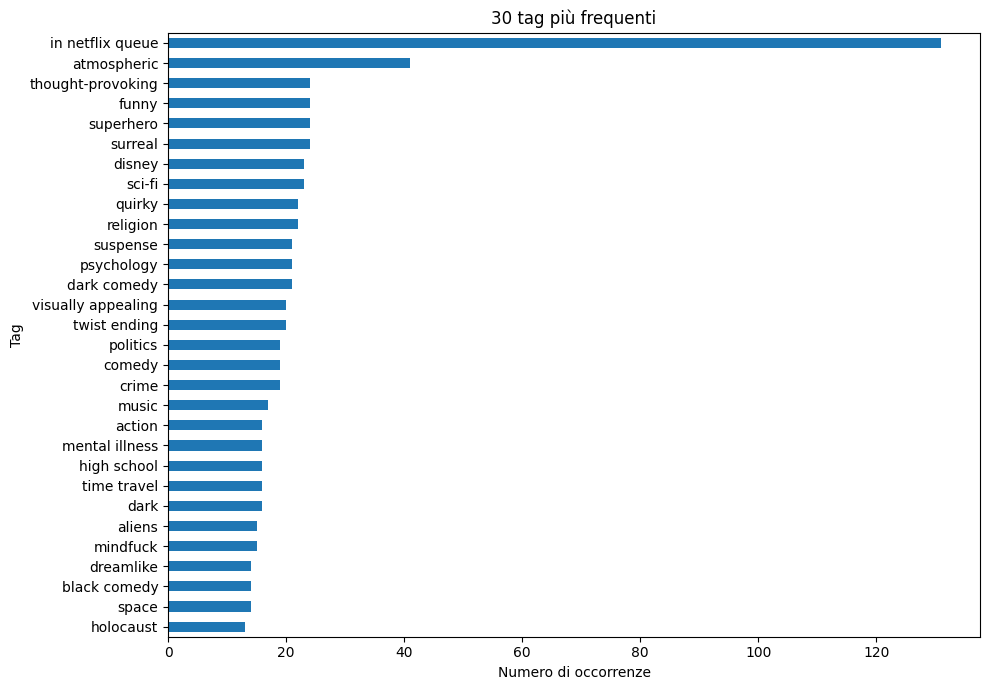

In [11]:

plt.figure(figsize=(10, 7))

top_tags.sort_values().plot(kind="barh")

plt.title("30 tag più frequenti")
plt.xlabel("Numero di occorrenze")
plt.ylabel("Tag")

plt.tight_layout()
plt.show()



## 5.1 Numero di tag per film


In [12]:

tags_per_movie = (
    tags.groupby("movieId")
    .size()
)

display(
    tags_per_movie.describe(
        percentiles=[0.25, 0.50, 0.75, 0.90, 0.95, 0.99]
    )
)


,0
count,1572.0000
mean,2.3429
std,5.5623
min,1.0000
25%,1.0000
50%,1.0000
75%,2.0000
90%,5.0000
95%,7.0000
99%,13.0000


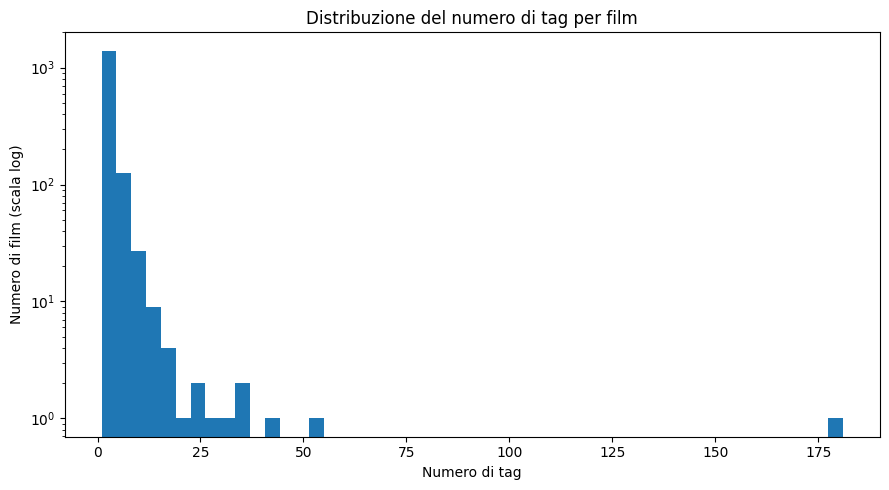

In [13]:

plt.figure(figsize=(9, 5))

plt.hist(tags_per_movie, bins=50)
plt.yscale("log")

plt.title("Distribuzione del numero di tag per film")
plt.xlabel("Numero di tag")
plt.ylabel("Numero di film (scala log)")

plt.tight_layout()
plt.show()



# 6. Preparazione dei metadata degli item

Per ciascun film costruiamo due rappresentazioni separate:

### Generi

Esempio:

`Action|Adventure|Sci-Fi`

diventa:

`action adventure sci_fi`

### Tag

Tutti i tag associati allo stesso film vengono aggregati in un unico testo.

Esempio:

`space, time travel, dystopia, mind-bending`

diventa:

`space time travel dystopia mind bending`

Successivamente useremo **due TF-IDF separati**, uno per i generi e uno per i tag.

Questo evita che il vocabolario molto più ricco dei tag renda irrilevante l'informazione strutturata dei generi.


In [14]:

def clean_token(text):
    text = str(text).lower().strip()
    text = re.sub(r"[^a-z0-9]+", "_", text)
    return text.strip("_")


movies_content = movies[
    ["movieId", "title", "genres"]
].copy()

movies_content["genres_text"] = (
    movies_content["genres"]
    .str.split("|")
    .apply(
        lambda values: " ".join(
            clean_token(v)
            for v in values
            if v != "(no genres listed)"
        )
    )
)

tag_documents = (
    tags.assign(
        tag_token=tags["tag_clean"].map(clean_token)
    )
    .groupby("movieId")["tag_token"]
    .apply(lambda x: " ".join(x))
    .rename("tags_text")
    .reset_index()
)

movies_content = movies_content.merge(
    tag_documents,
    on="movieId",
    how="left"
)

movies_content["tags_text"] = (
    movies_content["tags_text"]
    .fillna("")
)

display(movies_content.head(10))


,movieId,title,genres,genres_text,tags_text
0,1,Toy Story (1995),Adventure|Animation|Children|Comedy|Fantasy,adventure animation children comedy fantasy,pixar pixar fun
1,2,Jumanji (1995),Adventure|Children|Fantasy,adventure children fantasy,fantasy magic_board_game robin_williams game
2,3,Grumpier Old Men (1995),Comedy|Romance,comedy romance,moldy old
3,4,Waiting to Exhale (1995),Comedy|Drama|Romance,comedy drama romance,
4,5,Father of the Bride Part II (1995),Comedy,comedy,pregnancy remake
5,6,Heat (1995),Action|Crime|Thriller,action crime thriller,
6,7,Sabrina (1995),Comedy|Romance,comedy romance,remake
7,8,Tom and Huck (1995),Adventure|Children,adventure children,
8,9,Sudden Death (1995),Action,action,
9,10,GoldenEye (1995),Action|Adventure|Thriller,action adventure thriller,



## 6.1 Esempio della rappresentazione di un film


In [15]:

def search_movie(query, n=20):
    mask = movies_content["title"].str.contains(
        query,
        case=False,
        regex=False,
        na=False
    )

    return movies_content.loc[
        mask,
        ["movieId", "title", "genres_text", "tags_text"]
    ].head(n)

search_movie("Matrix")


,movieId,title,genres_text,tags_text
1939,2571,"Matrix, The (1999)",action sci_fi thriller,martial_arts sci_fi alternate_universe philoso...
4351,6365,"Matrix Reloaded, The (2003)",action adventure sci_fi thriller imax,
4639,6934,"Matrix Revolutions, The (2003)",action adventure sci_fi thriller imax,
5669,27660,"Animatrix, The (2003)",action animation drama sci_fi,animation anime cyberpunk dark matrix sci_fi



# 7. Vettorizzazione TF-IDF

Creiamo:

- una matrice TF-IDF per i **generi**;
- una matrice TF-IDF per i **tag**.

Poi le concateniamo.

Diamo leggermente più peso ai generi, perché:

- sono disponibili praticamente per tutto il catalogo;
- sono metadata strutturati;
- i tag hanno una copertura molto più limitata e sono user-generated.

Il parametro `GENRE_WEIGHT` potrà essere ottimizzato successivamente.


In [16]:

genre_vectorizer = TfidfVectorizer(
    token_pattern=r"(?u)\b\w+\b"
)

tag_vectorizer = TfidfVectorizer(
    token_pattern=r"(?u)\b\w+\b",
    min_df=2
)

genre_matrix = genre_vectorizer.fit_transform(
    movies_content["genres_text"]
)

tag_matrix = tag_vectorizer.fit_transform(
    movies_content["tags_text"]
)

print("Genre matrix:", genre_matrix.shape)
print("Tag matrix:", tag_matrix.shape)


Genre matrix: (9742, 19)
Tag matrix: (9742, 542)


In [17]:

GENRE_WEIGHT = 1.5
TAG_WEIGHT = 1.0

content_matrix = hstack(
    [
        genre_matrix * GENRE_WEIGHT,
        tag_matrix * TAG_WEIGHT
    ],
    format="csr"
)

print("Content matrix:", content_matrix.shape)
print("Numero totale di feature:", content_matrix.shape[1])


Content matrix: (9742, 561)
Numero totale di feature: 561



# 8. Similarità Content-Based tra film

La similarità tra due film viene calcolata tramite **cosine similarity** tra i loro vettori TF-IDF.

Qui il significato è completamente diverso rispetto all'Item-Based:

- **Item-Based CF** → due film sono simili se gli utenti li valutano in modo simile;
- **Content-Based** → due film sono simili se hanno caratteristiche di contenuto simili.


In [18]:

movie_ids = movies_content["movieId"].to_numpy()

movie_to_pos = {
    movie_id: pos
    for pos, movie_id in enumerate(movie_ids)
}

movie_lookup = movies_content.set_index("movieId")


In [19]:

def similar_movies_content(movie_id, n=10):
    if movie_id not in movie_to_pos:
        raise ValueError("movieId non presente nel catalogo.")

    pos = movie_to_pos[movie_id]

    similarities = cosine_similarity(
        content_matrix[pos],
        content_matrix
    ).ravel()

    similarities[pos] = -1

    order = np.argsort(similarities)[::-1][:n]

    rows = []

    for other_pos in order:
        other_movie_id = movie_ids[other_pos]

        rows.append({
            "movieId": other_movie_id,
            "title": movie_lookup.loc[other_movie_id, "title"],
            "genres": movie_lookup.loc[other_movie_id, "genres"],
            "similarity": float(similarities[other_pos])
        })

    return pd.DataFrame(rows)



## 8.1 Esempio: film simili a Toy Story


In [20]:

similar_movies_content(
    movie_id=1,
    n=10
)


,movieId,title,genres,similarity
0,2355,"Bug's Life, A (1998)",Adventure|Animation|Children|Comedy,0.8826
1,3114,Toy Story 2 (1999),Adventure|Animation|Children|Comedy|Fantasy,0.8751
2,4016,"Emperor's New Groove, The (2000)",Adventure|Animation|Children|Comedy|Fantasy,0.8321
3,91355,Asterix and the Vikings (Astérix et les Viking...,Adventure|Animation|Children|Comedy|Fantasy,0.8321
4,166461,Moana (2016),Adventure|Animation|Children|Comedy|Fantasy,0.8321
5,136016,The Good Dinosaur (2015),Adventure|Animation|Children|Comedy|Fantasy,0.8321
6,3754,"Adventures of Rocky and Bullwinkle, The (2000)",Adventure|Animation|Children|Comedy|Fantasy,0.8321
7,45074,"Wild, The (2006)",Adventure|Animation|Children|Comedy|Fantasy,0.8321
8,103755,Turbo (2013),Adventure|Animation|Children|Comedy|Fantasy,0.8321
9,4886,"Monsters, Inc. (2001)",Adventure|Animation|Children|Comedy|Fantasy,0.8321



## 8.2 Esempio: film simili a Matrix

Prima recuperiamo il `movieId`.


In [21]:

search_movie("Matrix", n=10)


,movieId,title,genres_text,tags_text
1939,2571,"Matrix, The (1999)",action sci_fi thriller,martial_arts sci_fi alternate_universe philoso...
4351,6365,"Matrix Reloaded, The (2003)",action adventure sci_fi thriller imax,
4639,6934,"Matrix Revolutions, The (2003)",action adventure sci_fi thriller imax,
5669,27660,"Animatrix, The (2003)",action animation drama sci_fi,animation anime cyberpunk dark matrix sci_fi


In [22]:

# Inserisci qui uno dei movieId restituiti dalla cella precedente
MATRIX_MOVIE_ID = 2571

similar_movies_content(
    MATRIX_MOVIE_ID,
    n=10
)


,movieId,title,genres,similarity
0,172,Johnny Mnemonic (1995),Action|Sci-Fi|Thriller,0.8321
1,76,Screamers (1995),Action|Sci-Fi|Thriller,0.8321
2,6574,Eve of Destruction (1991),Action|Sci-Fi|Thriller,0.8321
3,1882,Godzilla (1998),Action|Sci-Fi|Thriller,0.8321
4,4443,Outland (1981),Action|Sci-Fi|Thriller,0.8321
5,88699,Death Race 2 (2010),Action|Sci-Fi|Thriller,0.8321
6,79057,Predators (2010),Action|Sci-Fi|Thriller,0.8321
7,51412,Next (2007),Action|Sci-Fi|Thriller,0.8321
8,95875,Total Recall (2012),Action|Sci-Fi|Thriller,0.8321
9,130490,Insurgent (2015),Action|Sci-Fi|Thriller,0.8321



# 9. Profilo Content-Based dell'utente

Per generare raccomandazioni personalizzate dobbiamo trasformare la cronologia dell'utente in un **vettore che rappresenti i suoi gusti**.

Non utilizziamo tutti i film allo stesso modo.

Per ogni film già valutato calcoliamo:

\[
w_{u,i} = \max(r_{u,i} - \bar r_u,\ 0)
\]

In questo modo:

- un film valutato **sopra la media personale dell'utente** contribuisce positivamente al profilo;
- un film valutato sotto la media non viene interpretato come una preferenza.

Il profilo è quindi la media pesata dei vettori dei film apprezzati:

\[
Profile_u =
\frac{
\sum_i w_{u,i} \cdot ContentVector_i
}{
\sum_i w_{u,i}
}
\]


In [23]:

def build_user_content_profile(
    user_id,
    ratings_df,
    min_rating=4.0
):
    user_ratings = ratings_df[
        ratings_df["userId"] == user_id
    ].copy()

    if user_ratings.empty:
        return None

    user_mean = user_ratings["rating"].mean()

    liked = user_ratings[
        user_ratings["rating"] >= min_rating
    ].copy()

    liked = liked[
        liked["movieId"].isin(movie_to_pos)
    ]

    if liked.empty:
        return None

    positions = np.array([
        movie_to_pos[movie_id]
        for movie_id in liked["movieId"]
    ])

    weights = np.maximum(
        liked["rating"].to_numpy() - user_mean,
        0
    )

    # Se tutti i pesi diventano 0, usiamo il rating come peso
    if weights.sum() == 0:
        weights = liked["rating"].to_numpy()

    weighted_vectors = content_matrix[positions].multiply(
        weights[:, None]
    )

    profile = weighted_vectors.sum(axis=0) / weights.sum()

    return csr_matrix(profile)



# 10. Generazione delle raccomandazioni Content-Based

Per ogni film non ancora visto dall'utente calcoliamo:

\[
Score_{CB}(u,i) = cosine(Profile_u, ContentVector_i)
\]

e restituiamo i film con score più alto.


In [24]:

def content_scores_for_user(
    user_id,
    ratings_df,
    min_rating=4.0
):
    profile = build_user_content_profile(
        user_id,
        ratings_df,
        min_rating=min_rating
    )

    if profile is None:
        return None

    scores = cosine_similarity(
        profile,
        content_matrix
    ).ravel()

    return scores


In [25]:

def recommend_content_for_user(
    user_id,
    ratings_df,
    n=10,
    min_rating=4.0
):
    scores = content_scores_for_user(
        user_id,
        ratings_df,
        min_rating=min_rating
    )

    if scores is None:
        return pd.DataFrame()

    seen_movie_ids = set(
        ratings_df.loc[
            ratings_df["userId"] == user_id,
            "movieId"
        ]
    )

    candidate_positions = [
        pos
        for pos, movie_id in enumerate(movie_ids)
        if movie_id not in seen_movie_ids
    ]

    candidate_positions = sorted(
        candidate_positions,
        key=lambda pos: scores[pos],
        reverse=True
    )[:n]

    rows = []

    for pos in candidate_positions:
        movie_id = movie_ids[pos]

        rows.append({
            "movieId": movie_id,
            "title": movie_lookup.loc[movie_id, "title"],
            "genres": movie_lookup.loc[movie_id, "genres"],
            "content_score": float(scores[pos])
        })

    return pd.DataFrame(rows)



## 10.1 Profilo di un utente di esempio


In [26]:

USER_ID = 1

user_history = (
    ratings[
        ratings["userId"] == USER_ID
    ]
    .merge(
        movies[["movieId", "title", "genres"]],
        on="movieId",
        how="left"
    )
    .sort_values("rating", ascending=False)
)

display(user_history.head(20))


,userId,movieId,rating,timestamp,datetime,title,genres
3,1,47,5.0000,964983815,2000-07-30 19:03:35,Seven (a.k.a. Se7en) (1995),Mystery|Thriller
4,1,50,5.0000,964982931,2000-07-30 18:48:51,"Usual Suspects, The (1995)",Crime|Mystery|Thriller
6,1,101,5.0000,964980868,2000-07-30 18:14:28,Bottle Rocket (1996),Adventure|Comedy|Crime|Romance
13,1,231,5.0000,964981179,2000-07-30 18:19:39,Dumb & Dumber (Dumb and Dumber) (1994),Adventure|Comedy
11,1,216,5.0000,964981208,2000-07-30 18:20:08,Billy Madison (1995),Comedy
10,1,163,5.0000,964983650,2000-07-30 19:00:50,Desperado (1995),Action|Romance|Western
9,1,157,5.0000,964984100,2000-07-30 19:08:20,Canadian Bacon (1995),Comedy|War
8,1,151,5.0000,964984041,2000-07-30 19:07:21,Rob Roy (1995),Action|Drama|Romance|War
35,1,596,5.0000,964982838,2000-07-30 18:47:18,Pinocchio (1940),Animation|Children|Fantasy|Musical
31,1,553,5.0000,964984153,2000-07-30 19:09:13,Tombstone (1993),Action|Drama|Western



## 10.2 Raccomandazioni per l'utente


In [27]:

content_recommendations = recommend_content_for_user(
    USER_ID,
    ratings,
    n=10,
    min_rating=4.0
)

display(content_recommendations)


,movieId,title,genres,content_score
0,5657,Flashback (1990),Action|Adventure|Comedy|Crime|Drama,0.7733
1,6990,The Great Train Robbery (1978),Action|Adventure|Comedy|Crime|Drama,0.7733
2,55116,"Hunting Party, The (2007)",Action|Adventure|Comedy|Drama|Thriller,0.7639
3,117646,Dragonheart 2: A New Beginning (2000),Action|Adventure|Comedy|Drama|Fantasy|Thriller,0.7627
4,6503,Charlie's Angels: Full Throttle (2003),Action|Adventure|Comedy|Crime|Thriller,0.7438
5,8968,After the Sunset (2004),Action|Adventure|Comedy|Crime|Thriller,0.7438
6,26184,"Diamond Arm, The (Brilliantovaya ruka) (1968)",Action|Adventure|Comedy|Crime|Thriller,0.7438
7,80219,Machete (2010),Action|Adventure|Comedy|Crime|Thriller,0.7438
8,4818,Extreme Days (2001),Action|Adventure|Comedy|Drama,0.7438
9,7262,Catch That Kid (2004),Action|Adventure|Children|Comedy|Crime,0.7404



# 11. Analisi qualitativa delle raccomandazioni

Per capire *perché* un film viene raccomandato, possiamo confrontare i suoi generi e tag con quelli dei film apprezzati dall'utente.

Questo è uno dei vantaggi del Content-Based: la raccomandazione è relativamente interpretabile.


In [28]:

liked_movies = (
    user_history[
        user_history["rating"] >= 4.0
    ]
    [["movieId", "title", "genres", "rating"]]
    .head(15)
)

display(liked_movies)

display(
    content_recommendations[
        ["movieId", "title", "genres", "content_score"]
    ]
)


,movieId,title,genres,rating
3,47,Seven (a.k.a. Se7en) (1995),Mystery|Thriller,5.0000
4,50,"Usual Suspects, The (1995)",Crime|Mystery|Thriller,5.0000
6,101,Bottle Rocket (1996),Adventure|Comedy|Crime|Romance,5.0000
13,231,Dumb & Dumber (Dumb and Dumber) (1994),Adventure|Comedy,5.0000
11,216,Billy Madison (1995),Comedy,5.0000
10,163,Desperado (1995),Action|Romance|Western,5.0000
9,157,Canadian Bacon (1995),Comedy|War,5.0000
8,151,Rob Roy (1995),Action|Drama|Romance|War,5.0000
35,596,Pinocchio (1940),Animation|Children|Fantasy|Musical,5.0000
31,553,Tombstone (1993),Action|Drama|Western,5.0000


,movieId,title,genres,content_score
0,5657,Flashback (1990),Action|Adventure|Comedy|Crime|Drama,0.7733
1,6990,The Great Train Robbery (1978),Action|Adventure|Comedy|Crime|Drama,0.7733
2,55116,"Hunting Party, The (2007)",Action|Adventure|Comedy|Drama|Thriller,0.7639
3,117646,Dragonheart 2: A New Beginning (2000),Action|Adventure|Comedy|Drama|Fantasy|Thriller,0.7627
4,6503,Charlie's Angels: Full Throttle (2003),Action|Adventure|Comedy|Crime|Thriller,0.7438
5,8968,After the Sunset (2004),Action|Adventure|Comedy|Crime|Thriller,0.7438
6,26184,"Diamond Arm, The (Brilliantovaya ruka) (1968)",Action|Adventure|Comedy|Crime|Thriller,0.7438
7,80219,Machete (2010),Action|Adventure|Comedy|Crime|Thriller,0.7438
8,4818,Extreme Days (2001),Action|Adventure|Comedy|Drama,0.7438
9,7262,Catch That Kid (2004),Action|Adventure|Children|Comedy|Crime,0.7404



# 12. Baseline di popolarità

Come nel notebook Item-Based, utilizziamo una baseline semplice che raccomanda i film con più rating nel training set.


In [29]:

def popularity_recommendations(
    train_ratings,
    user_id,
    candidate_movie_ids,
    n=10
):
    seen = set(
        train_ratings.loc[
            train_ratings["userId"] == user_id,
            "movieId"
        ]
    )

    popularity = (
        train_ratings[
            train_ratings["movieId"].isin(candidate_movie_ids)
        ]
        .groupby("movieId")
        .size()
        .sort_values(ascending=False)
    )

    return [
        movie_id
        for movie_id in popularity.index
        if movie_id not in seen
    ][:n]



# 13. Valutazione offline

Manteniamo lo **stesso protocollo dell'Item-Based**, così le metriche dei due modelli saranno confrontabili.

Per ciascun utente:

1. ordiniamo i rating temporalmente;
2. l'ultimo rating viene usato come test;
3. gli altri rating costituiscono il training;
4. consideriamo rilevante il test item se ha rating >= 4.

Il profilo Content-Based dell'utente viene costruito **solo dai rating del training set**.


In [30]:

ratings_sorted = ratings.sort_values(
    ["userId", "timestamp"]
)

test_indices = (
    ratings_sorted
    .groupby("userId")
    .tail(1)
    .index
)

test_ratings = ratings_sorted.loc[
    test_indices
].copy()

train_ratings = ratings_sorted.drop(
    index=test_indices
).copy()

print("Training interactions:", len(train_ratings))
print("Test interactions:", len(test_ratings))


Training interactions: 100226
Test interactions: 610



## 13.1 Utenti valutabili

Consideriamo soltanto:

- utenti il cui ultimo rating è >= 4;
- utenti per cui è possibile costruire un profilo Content-Based dal training set.


In [31]:

RELEVANCE_THRESHOLD = 4.0

positive_test = test_ratings[
    test_ratings["rating"] >= RELEVANCE_THRESHOLD
].copy()

eligible_users = []

for user_id in positive_test["userId"].unique():

    profile = build_user_content_profile(
        user_id,
        train_ratings,
        min_rating=RELEVANCE_THRESHOLD
    )

    if profile is not None:
        eligible_users.append(user_id)

eligible_users = sorted(eligible_users)

print("Utenti totali:", ratings["userId"].nunique())
print(
    "Utenti con ultimo rating >= 4:",
    positive_test["userId"].nunique()
)
print(
    "Utenti effettivamente valutabili:",
    len(eligible_users)
)


Utenti totali: 610
Utenti con ultimo rating >= 4: 363
Utenti effettivamente valutabili: 363



# 14. Metriche Top-N

Calcoliamo:

- HitRate@K;
- Precision@K;
- Recall@K;
- MRR@K;
- NDCG@K;
- CatalogCoverage@K.

Con un solo item rilevante per utente, **HitRate@K e Recall@K coincidono**.


In [32]:

def evaluate_recommender(
    get_recommendations,
    test_df,
    users,
    catalog_movie_ids,
    k=10
):
    test_lookup = (
        test_df
        .set_index("userId")["movieId"]
        .to_dict()
    )

    hits = []
    reciprocal_ranks = []
    ndcgs = []
    all_recommended = set()

    evaluated = 0

    for user_id in users:
        true_movie = test_lookup[user_id]

        recs = get_recommendations(
            user_id,
            k
        )

        if len(recs) == 0:
            continue

        evaluated += 1
        all_recommended.update(recs)

        if true_movie in recs:
            rank = recs.index(true_movie) + 1

            hits.append(1)
            reciprocal_ranks.append(1 / rank)
            ndcgs.append(1 / np.log2(rank + 1))
        else:
            hits.append(0)
            reciprocal_ranks.append(0)
            ndcgs.append(0)

    if evaluated == 0:
        raise ValueError("Nessun utente valutabile.")

    hit_rate = np.mean(hits)

    precision = (
        np.sum(hits)
        / (evaluated * k)
    )

    recall = hit_rate
    mrr = np.mean(reciprocal_ranks)
    ndcg = np.mean(ndcgs)

    coverage = (
        len(all_recommended)
        / len(catalog_movie_ids)
    )

    return {
        "n_utenti_valutati": evaluated,
        f"HitRate@{k}": hit_rate,
        f"Precision@{k}": precision,
        f"Recall@{k}": recall,
        f"MRR@{k}": mrr,
        f"NDCG@{k}": ndcg,
        f"CatalogCoverage@{k}": coverage
    }



# 15. Evaluation del Content-Based


In [33]:

K = 10

def content_get_recs(user_id, k):
    recs = recommend_content_for_user(
        user_id=user_id,
        ratings_df=train_ratings,
        n=k,
        min_rating=RELEVANCE_THRESHOLD
    )

    if recs.empty:
        return []

    return recs["movieId"].tolist()


content_metrics = evaluate_recommender(
    get_recommendations=content_get_recs,
    test_df=positive_test,
    users=eligible_users,
    catalog_movie_ids=movie_ids,
    k=K
)

content_metrics_df = pd.DataFrame(
    content_metrics,
    index=["Content-Based"]
).T

display(content_metrics_df)


,Content-Based
n_utenti_valutati,363.0000
HitRate@10,0.0028
Precision@10,0.0003
Recall@10,0.0028
MRR@10,0.0009
NDCG@10,0.0014
CatalogCoverage@10,0.0809



# 16. Evaluation della baseline di popolarità


In [34]:

def popularity_get_recs(user_id, k):
    return popularity_recommendations(
        train_ratings,
        user_id=user_id,
        candidate_movie_ids=movie_ids,
        n=k
    )


pop_metrics = evaluate_recommender(
    get_recommendations=popularity_get_recs,
    test_df=positive_test,
    users=eligible_users,
    catalog_movie_ids=movie_ids,
    k=K
)

pop_metrics_df = pd.DataFrame(
    pop_metrics,
    index=["Popularity"]
).T

display(pop_metrics_df)


,Popularity
n_utenti_valutati,363.0000
HitRate@10,0.0634
Precision@10,0.0063
Recall@10,0.0634
MRR@10,0.0198
NDCG@10,0.0299
CatalogCoverage@10,0.0098



# 17. Confronto Content-Based vs baseline


In [35]:

comparison = pd.DataFrame({
    "Content-Based": content_metrics,
    "Popularity": pop_metrics
})

display(comparison)


,Content-Based,Popularity
n_utenti_valutati,363.0000,363.0000
HitRate@10,0.0028,0.0634
Precision@10,0.0003,0.0063
Recall@10,0.0028,0.0634
MRR@10,0.0009,0.0198
NDCG@10,0.0014,0.0299
CatalogCoverage@10,0.0809,0.0098


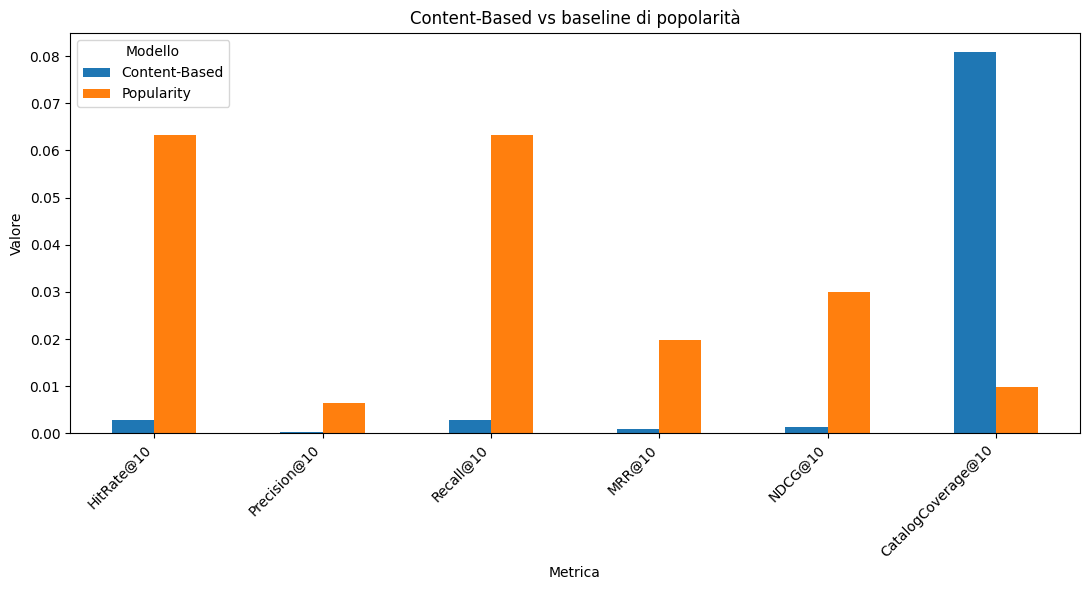

In [36]:

metric_names = [
    f"HitRate@{K}",
    f"Precision@{K}",
    f"Recall@{K}",
    f"MRR@{K}",
    f"NDCG@{K}",
    f"CatalogCoverage@{K}"
]

plot_df = comparison.loc[metric_names]

plot_df.plot(
    kind="bar",
    figsize=(11, 6)
)

plt.title("Content-Based vs baseline di popolarità")
plt.ylabel("Valore")
plt.xlabel("Metrica")
plt.xticks(rotation=45, ha="right")
plt.legend(title="Modello")

plt.tight_layout()
plt.show()



# 18. Score da conservare per il sistema ibrido

Il notebook espone già la funzione:

```python
content_scores_for_user(user_id, ratings_df)
```

che restituisce uno **score Content-Based per ogni film del catalogo**.

Nel notebook successivo faremo la stessa cosa con l'Item-Based, normalizzeremo i due score su una scala confrontabile e costruiremo:

\[
Score_{Hybrid}(u,i)
=
\alpha Score_{CF}(u,i)
+
(1-\alpha) Score_{CB}(u,i)
\]

Potremo poi testare diversi valori di \(lpha\), ad esempio:

- 0.2
- 0.4
- 0.5
- 0.6
- 0.8

e scegliere la combinazione sulla base delle metriche di validation, senza assumere a priori che uno dei due modelli debba pesare di più.



# 19. Considerazioni finali

La pipeline Content-Based realizzata comprende:

1. analisi dei metadata;
2. studio della distribuzione dei generi;
3. studio dei tag;
4. aggregazione dei metadata per film;
5. TF-IDF separato per generi e tag;
6. fusione delle feature;
7. similarità Content-Based film-film;
8. profilo contenutistico dell'utente;
9. raccomandazioni Top-N;
10. split temporale;
11. valutazione offline;
12. confronto con baseline;
13. funzione di scoring già predisposta per l'ibridazione.

## Importante

Non ci aspettiamo necessariamente che il Content-Based, da solo, ottenga metriche eccezionali.

In `ml-latest-small` l'informazione di contenuto è abbastanza limitata:

- i generi sono pochi e molto generici;
- solo una parte dei film possiede tag;
- non abbiamo trama, cast, regista o descrizioni complete.

Il punto interessante del progetto sarà quindi verificare se **CF e Content-Based commettono errori diversi** e se la loro combinazione migliora il ranking finale.
